In [20]:
import pandas as pd

from google.colab import files
files.upload()

Saving penguins.csv to penguins (2).csv


{'penguins (2).csv': b'species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year\nAdelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007\nAdelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007\nAdelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007\nAdelie,Torgersen,,,,,,2007\nAdelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007\nAdelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007\nAdelie,Torgersen,38.9,17.8,181.0,3625.0,female,2007\nAdelie,Torgersen,39.2,19.6,195.0,4675.0,male,2007\nAdelie,Torgersen,34.1,18.1,193.0,3475.0,,2007\nAdelie,Torgersen,42.0,20.2,190.0,4250.0,,2007\nAdelie,Torgersen,37.8,17.1,186.0,3300.0,,2007\nAdelie,Torgersen,37.8,17.3,180.0,3700.0,,2007\nAdelie,Torgersen,41.1,17.6,182.0,3200.0,female,2007\nAdelie,Torgersen,38.6,21.2,191.0,3800.0,male,2007\nAdelie,Torgersen,34.6,21.1,198.0,4400.0,male,2007\nAdelie,Torgersen,36.6,17.8,185.0,3700.0,female,2007\nAdelie,Torgersen,38.7,19.0,195.0,3450.0,female,2007\nAdelie,Torgersen,42.5,20.7,197.0,4500.0,male,2007\n

In [21]:
df = pd.read_csv("penguins.csv")

df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
...,...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009


In [22]:
df.shape

(344, 8)

In [23]:
df.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0


In [24]:
df['species'].value_counts()

,count
species,
Adelie,152
Gentoo,124
Chinstrap,68


Prompt Log:

You are helping with exploratory data analysis.
My CSV has columns: [species 	island 	bill_length_mm 	bill_depth_mm 	flipper_length_mm 	body_mass_g 	sex 	year + str str float float float float str int].
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare [flipper length] across [species],
(3) produce one labeled chart.
Explain each step in comments.

Missing Data Summary:
                   Missing Count  Missing Percentage (%)
species                        0                    0.00
island                         0                    0.00
bill_length_mm                 2                    0.58
bill_depth_mm                  2                    0.58
flipper_length_mm              2                    0.58
body_mass_g                    2                    0.58
sex                           11                    3.20
year                           0                    0.00

Flipper Length by Species:
           count    mean  median   std
species                               
Adelie       151  189.95   190.0  6.54
Chinstrap     68  195.82   196.0  7.13
Gentoo       123  217.19   216.0  6.48


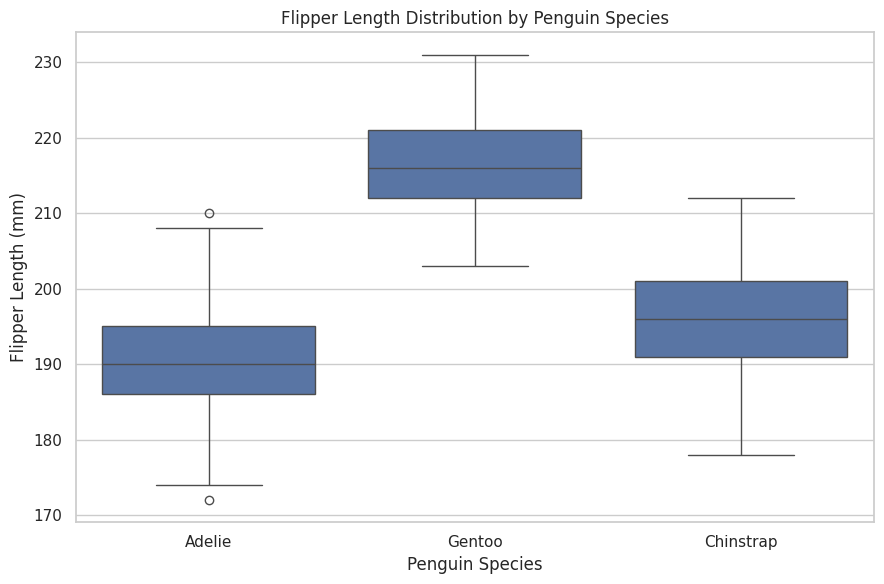

In [25]:
# Import the libraries needed for data analysis and visualization
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the CSV file into a pandas DataFrame
df = pd.read_csv("penguins.csv")

# --------------------------------------------------
# 1. Summarize missing data
# --------------------------------------------------

# Count missing values in each column
missing_counts = df.isnull().sum()

# Calculate the percentage of missing values in each column
missing_percentages = (df.isnull().mean() * 100).round(2)

# Combine the counts and percentages into one summary table
missing_summary = pd.DataFrame({
    "Missing Count": missing_counts,
    "Missing Percentage (%)": missing_percentages
})

# Display the missing-data summary for all columns
print("Missing Data Summary:")
print(missing_summary)

# --------------------------------------------------
# 2. Compare flipper length across species
# --------------------------------------------------

# Group the data by species and calculate summary statistics
# for flipper length, including count, mean, median, and standard deviation
flipper_summary = df.groupby("species")["flipper_length_mm"].agg(
    ["count", "mean", "median", "std"]
).round(2)

# Display the summary statistics for each species
print("\nFlipper Length by Species:")
print(flipper_summary)

# --------------------------------------------------
# 3. Produce one labeled chart
# --------------------------------------------------

# Set a seaborn theme to make the chart easier to read
sns.set_theme(style="whitegrid")

# Create a boxplot to compare flipper lengths across species
# A boxplot shows the median, spread, and potential outliers
plt.figure(figsize=(9, 6))
sns.boxplot(
    data=df,
    x="species",
    y="flipper_length_mm"
)

# Add a descriptive title and axis labels
plt.title("Flipper Length Distribution by Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Flipper Length (mm)")

# Adjust spacing so labels and titles fit neatly
plt.tight_layout()

# Display the chart
plt.show()

In [26]:
df.groupby("species")["flipper_length_mm"].mean()

,flipper_length_mm
species,
Adelie,189.953642
Chinstrap,195.823529
Gentoo,217.186992


The average flipper length for Adelie that I computed was around 189.95 mm. The average flipper length for Adelie that AI computed was around 189.95. Both numbers agree and match since they both accounted for the two missing values under flipper_length_mm column.

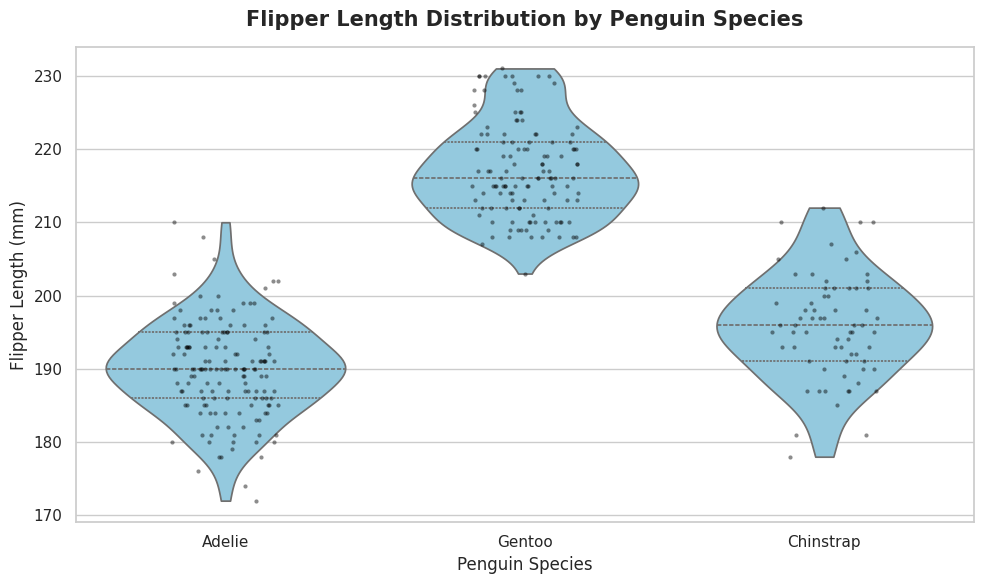

In [27]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the penguins dataset
df = pd.read_csv("penguins.csv")

# Remove rows missing species or flipper length so the chart can be plotted
plot_df = df.dropna(subset=["species", "flipper_length_mm"])

# Set a clean chart style
sns.set_theme(style="whitegrid", context="notebook")

# Create the figure
plt.figure(figsize=(10, 6))

# Draw a violin plot to show the distribution of flipper lengths
sns.violinplot(
    data=plot_df,
    x="species",
    y="flipper_length_mm",
    inner="quartile",
    cut=0,
    color="skyblue"
)

# Add individual observations on top of the violins
sns.stripplot(
    data=plot_df,
    x="species",
    y="flipper_length_mm",
    color="black",
    alpha=0.45,
    jitter=0.18,
    size=3
)

# Add a descriptive title and clear axis labels
plt.title("Flipper Length Distribution by Penguin Species",
          fontsize=15, weight="bold", pad=15)
plt.xlabel("Penguin Species", fontsize=12)
plt.ylabel("Flipper Length (mm)", fontsize=12)

# Improve readability and display the chart
plt.tight_layout()
plt.show()

I choose to reject the suggestion of creating violin plot because it doesn't seem to add clarity or make it easier to read/interpret the data.

One insight about penguins the AI did not state is that it decided to drop one more row for Adelie and one more row for Gentoo. When I ran df['species'].value_counts(), Adelie and Gentoo each had one more value.

One dataset from my own life could be home address. It could be dangerous to paste home address into a public AI tool, so I would use the name of the city or county instead.